### IMDB Sentiment Classifier with BERT (Bidirectional Encoder Representational from Transformer)

In [2]:
# Import libraries
import random
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from datasets        import load_dataset
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
from transformers    import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

/home/khadim/Desktop/PROJECTS/IMDB_SENTIMENT_ANALYSIS/.venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# For reproductibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [3]:
# Load the dataset
dataset = load_dataset("stanfordnlp/imdb")

In [ ]:
# Summary
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [5]:
# Print a sample
print(f"Review: {dataset["train"][0]["text"]}")
print(f"Label : {dataset["train"][0]["label"]}")
print("So 0 = negative & 1 = positive")

Review: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far betw

In [ ]:
# Splits (Train/Test/Val)
TRAIN_SIZE = 2000
TEST_SIZE  = 500

train = dataset["train"].shuffle(seed=SEED).select(range(TRAIN_SIZE))
test  = dataset["train"].shuffle(seed=SEED).select(range(TEST_SIZE))

split    = train.train_test_split(test_size=0.1, seed=SEED)
train_ds = split["train"]
val_ds  = split["test"]

print(f"Train size = {len(train)}")
print(f"Val size   = {len(val_ds)}")
print(f"Test size  = {len(test)}")

Train size = 2000
Val size   = 200
Test size  = 500


In [6]:
# Tokenizing the text
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 256

# Load the tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Utils function for tokenizing the text
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

# Tokenize all the sets
train_tokenized = train_ds.map(tokenize, batched=True)
val_tokenized   = val_ds.map(tokenize, batched=True)
test_tokenized  = test.map(tokenize, batched=True)

NameError: name 'train_ds' is not defined

In [8]:
# Test
message = "Hi, my name is Khadim. I'm a Big Data & AI engineering student"
tokenizer(message)

{'input_ids': [101, 7632, 1010, 2026, 2171, 2003, 1047, 16102, 5714, 1012, 1045, 1005, 1049, 1037, 2502, 2951, 1004, 9932, 3330, 3076, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [9]:
# Load Pre-trained BERT for Classification
classifier = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 640.52it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoin

In [10]:
print(classifier)

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

In [11]:
# Metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return{
        "accuracy": accuracy_score(labels, preds),
        "f1_score": f1_score(labels, preds)
    }

In [12]:
# Data collator for padding "<pad>"
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [17]:
# Configs
training_args = TrainingArguments(
    output_dir="./bert_imdb_output",
    eval_strategy="epoch",
    learning_rate=2e-5,
    per_device_eval_batch_size=8,
    per_device_train_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,
    report_to='none',
    seed=SEED,
    logging_steps=50
)

trainer = Trainer(
    model=classifier,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [18]:
# Fine-Tunning the model
trainer.train()

/home/khadim/Desktop/PROJECTS/IMDB_SENTIMENT_ANALYSIS/.venv/lib64/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Score
1,0.166730,0.490878,0.890000,0.880435
2,0.212085,0.524302,0.875000,0.869110
3,0.081082,0.605524,0.870000,0.868687


/home/khadim/Desktop/PROJECTS/IMDB_SENTIMENT_ANALYSIS/.venv/lib64/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/home/khadim/Desktop/PROJECTS/IMDB_SENTIMENT_ANALYSIS/.venv/lib64/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  7.57it/s]
/home/khadim/Desktop/PROJECTS/IMDB_SENTIMENT_ANALYSIS/.venv/lib64/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=675, training_loss=0.16271044236642343, metrics={'train_runtime': 10701.6893, 'train_samples_per_second': 0.505, 'train_steps_per_second': 0.063, 'total_flos': 709614627416160.0, 'train_loss': 0.16271044236642343, 'epoch': 3.0})

In [29]:
idx2label = {0: "negative", 1: "positive"}

def predict_sentiment(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=MAX_LENGTH)

    classifier.eval()
    with torch.no_grad():
        logits = classifier(**inputs).logits

    proba   = torch.softmax(logits, dim=-1)[0]
    pred_id = torch.argmax(proba).item()

    return {
        "label": idx2label[pred_id],
        "confidence": round(proba[pred_id].item(), 4)
    }

In [46]:
# Test
for i in range(10):
    sentiment = test[i]['text']
    label     = test[i]['label']
    print(f"Sentiment: {sentiment[:15]:10} - label: {idx2label[label]:5} - Predicted Label: {predict_sentiment(sentiment)}")

Sentiment: There is no rel - label: positive - Predicted Label: {'label': 'positive', 'confidence': 0.9973}
Sentiment: This movie is a - label: positive - Predicted Label: {'label': 'positive', 'confidence': 0.9985}
Sentiment: George P. Cosma - label: negative - Predicted Label: {'label': 'negative', 'confidence': 0.9983}
Sentiment: In the process  - label: positive - Predicted Label: {'label': 'negative', 'confidence': 0.9912}
Sentiment: Yeh, I know --  - label: negative - Predicted Label: {'label': 'negative', 'confidence': 0.9986}
Sentiment: While this movi - label: positive - Predicted Label: {'label': 'positive', 'confidence': 0.9984}
Sentiment: I give this mov - label: positive - Predicted Label: {'label': 'positive', 'confidence': 0.9974}
Sentiment: really awful... - label: negative - Predicted Label: {'label': 'negative', 'confidence': 0.9983}
Sentiment: Good grief I ca - label: negative - Predicted Label: {'label': 'negative', 'confidence': 0.9983}
Sentiment: Home Room deals -

              precision    recall  f1-score   support

    negative       0.98      0.97      0.97       254
    positive       0.97      0.98      0.97       246

    accuracy                           0.97       500
   macro avg       0.97      0.97      0.97       500
weighted avg       0.97      0.97      0.97       500



Text(50.83333333333333, 0.5, 'Actual')

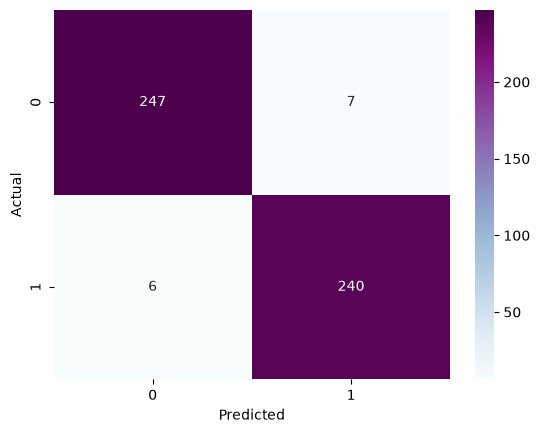

In [ ]:
# Evaluation
y_true = [idx2label[label] for label in test['label']]
y_pred = [predict_sentiment(text)['label'] for text in test['text']]

# Classification report
print(classification_report(y_true, y_pred))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Visualization
sns.heatmap(cm, annot=True, fmt='d', cmap='BuPu')
plt.xlabel('Predicted')
plt.ylabel('Actual')

In [19]:
# Saving the model
SAVE_DIR="./outputs/models/imdb_bert"

trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

print(f"model and tokenizer saved to: {SAVE_DIR}")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.14it/s]


model and tokenizer saved to: ./outputs/models/imdb_bert


In [4]:
# Load the saved model for testing
MODEL_PATH = "outputs/models/imdb_bert"

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)

model.eval()

device = torch.device("cpu")
model.to(device)

print("Tokenizer loaded :", tokenizer is not None)
print("Model loaded :", model is not None)
print("Device :", next(model.parameters()).device)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 2131.77it/s]

Tokenizer loaded : True
Model loaded : True
Device : cpu


In [5]:
# Test if that's working
text = "This movie was absolutely amazing. I loved every minute!"

inputs = tokenizer(
    text,
    return_tensors="pt",
    truncation=True,
    max_length=MAX_LENGTH
)

inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probabilities = torch.softmax(outputs.logits, dim=1)

predicted_class = torch.argmax(probabilities, dim=1).item()

print("Sentiment :", idx2label[predicted_class])
print("Probabilités :", probabilities.tolist())

NameError: name 'MAX_LENGTH' is not defined